## Introduction to tephigrams

Thermodynamic diagrams show the vertical structure of the atmosphere above a
point, such as a radiosonde sounding or a forecast profile. earthkit-plots
provides three of them: `Tephigram`, `SkewT` and `Emagram`. They share the
same methods, so everything in this notebook works with all three.

On a tephigram the temperature increases to the right and the potential
temperature upwards, so the isotherms and dry adiabats form a square grid
rotated by 45°. The isobars are the gently curved lines, labelled with the
pressure in hPa. The background also shows saturated adiabats and saturation
mixing ratio lines.

In [1]:
import earthkit.plots as ekp

### The data

A profile is just a list of values and the pressures they are on. Here the
temperature and dewpoint are in °C on the same pressure levels (hPa), and the
wind components (m/s) are on levels of their own.

In [2]:
# Pressure levels (hPa) of the temperature and dewpoint profiles
pressure = [
    977, 899, 849, 823, 810, 802, 771, 720, 693, 604, 587, 567, 559, 539, 505,
    492, 461, 453, 447, 433, 424, 402, 398, 383, 312, 297, 273, 264, 252, 215,
    208, 182, 175, 158, 155, 153, 149, 145, 142, 140, 130, 121, 109, 104,
]

# Temperature (°C)
temperature = [
    25.8, 18.8, 15.0, 14.0, 15.4, 15.8, 14.4, 9.6, 7.0, -2.5, -4.5, -5.3, -5.5,
    -8.1, -10.5, -12.1, -16.1, -17.1, -18.1, -19.7, -20.5, -23.9, -23.9, -25.7,
    -37.3, -39.7, -44.1, -45.9, -48.3, -55.9, -57.7, -62.3, -66.1, -67.9, -65.7,
    -65.7, -64.1, -64.5, -64.3, -63.5, -64.3, -66.7, -67.1, -68.3,
]

# Dewpoint (°C)
dewpoint = [
    10.8, 8.8, 6.0, 3.0, -20.6, -27.2, -23.6, -25.4, -12.0, -17.5, -14.5, -31.3,
    -32.5, -35.1, -45.5, -42.1, -30.1, -24.1, -23.1, -27.7, -38.5, -42.9, -57.9,
    -57.7, -67.3, -51.7, -55.1, -53.9, -59.3, -65.9, -71.7, -72.3, -76.1, -80.9,
    -81.7, -82.7, -85.1, -89.5, -93.3, -93.5, -94.3, -95.7, -96.1, -97.3,
]

# Wind components (m/s) on their own pressure levels (hPa)
wind_pressure = [989, 925, 850, 700, 500, 400, 300, 250]
u = [-3.856726, -4.588612, 1.91013, -2.871835e-08, 11.27631, 13.59462, 19.92389, 21.66577]
v = [4.596267, 6.553216, 10.83289, 8, 4.104242, 6.339274, 1.743115, 3.82026]

### Plotting the temperature and dewpoint

Create a `Tephigram`, then plot each profile with `temperature` and
`dewpoint`, passing its pressure levels with `p`. Any other keyword arguments
style the lines, as for matplotlib.

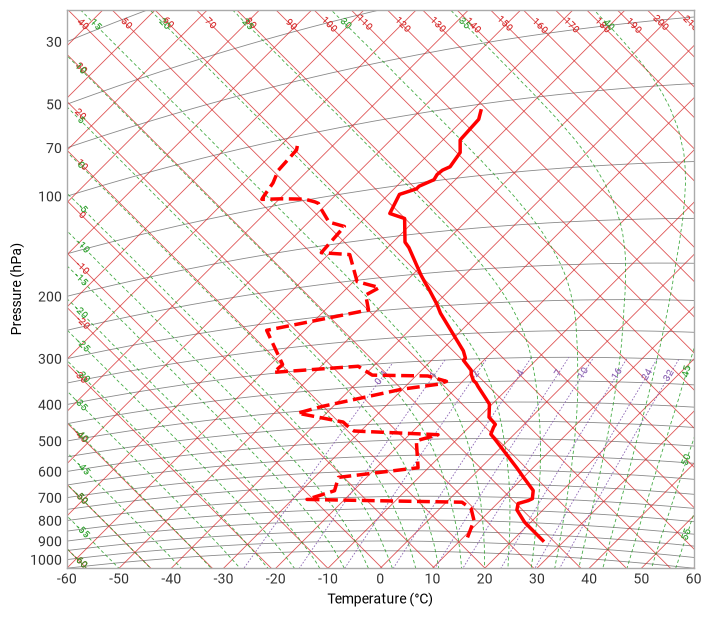

In [3]:
tephi = ekp.Tephigram()

tephi.temperature(temperature, p=pressure, color="red", linewidth=2.5)
tephi.dewpoint(dewpoint, p=pressure, color="red", linestyle="--", linewidth=2.5)

tephi.show()

Values in other units are converted with `units` and `p_units`: e.g.
`tephi.temperature(t_kelvin, p=p_pa, units="K", p_units="Pa")`.

### Adding wind barbs

`wind` draws a column of wind barbs from the `u` and `v` components (or
`speed` and `direction`). By default the barbs are in knots, and `position`
sets the horizontal position of the column as a fraction of the width of the
diagram.

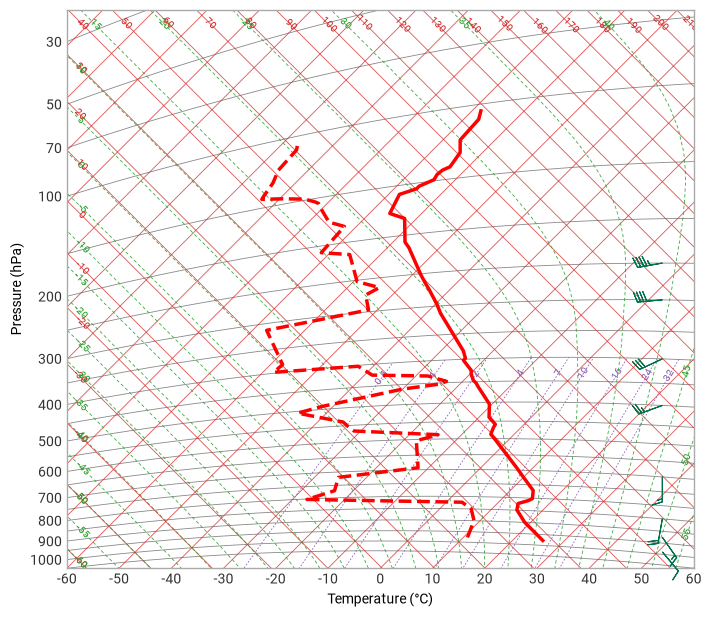

In [4]:
tephi = ekp.Tephigram()

tephi.temperature(temperature, p=pressure, color="red", linewidth=2.5)
tephi.dewpoint(dewpoint, p=pressure, color="red", linestyle="--", linewidth=2.5)
tephi.wind(u, v, p=wind_pressure, color="#00734d", position=0.95)

tephi.show()

With `panel=True` the barbs are drawn in a side panel to the right of the
diagram instead, which shares its pressure scale.

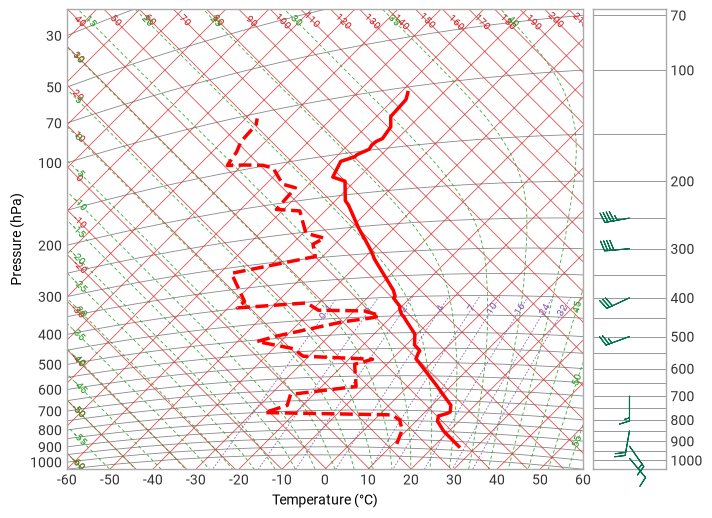

In [5]:
tephi = ekp.Tephigram()

tephi.temperature(temperature, p=pressure, color="red", linewidth=2.5)
tephi.dewpoint(dewpoint, p=pressure, color="red", linestyle="--", linewidth=2.5)
tephi.wind(u, v, p=wind_pressure, color="#00734d", panel=True)

tephi.show()

### Changing the extent and background lines

`temperature_range` (°C) and `pressure_range` (hPa, from the bottom to the top)
set the extent of the diagram, for example to look at the lower troposphere.
`grid` switches families of background lines on or off: here the saturation
mixing ratio lines are removed.

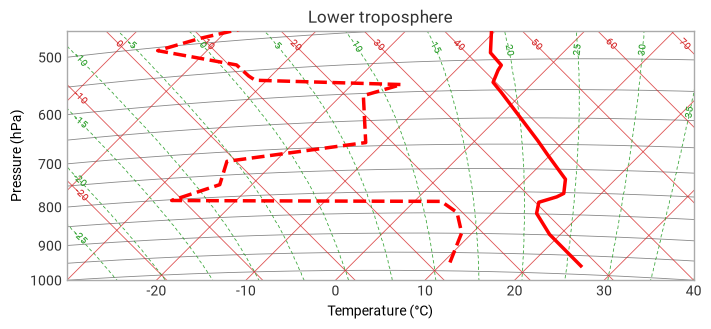

In [6]:
tephi = ekp.Tephigram(temperature_range=(-30, 40), pressure_range=(1000, 500))
tephi.grid(mixing_ratios=False)

tephi.temperature(temperature, p=pressure, color="red", linewidth=2.5)
tephi.dewpoint(dewpoint, p=pressure, color="red", linestyle="--", linewidth=2.5)
tephi.title("Lower troposphere")

tephi.show()

### Other diagrams

The same code draws a skew-T log-p diagram, with straight horizontal isobars
and skewed isotherms; use `ekp.Emagram()` for an emagram. See
[Skew-T and emagram diagrams](thermodynamic-skewt-emagram.ipynb) for more.

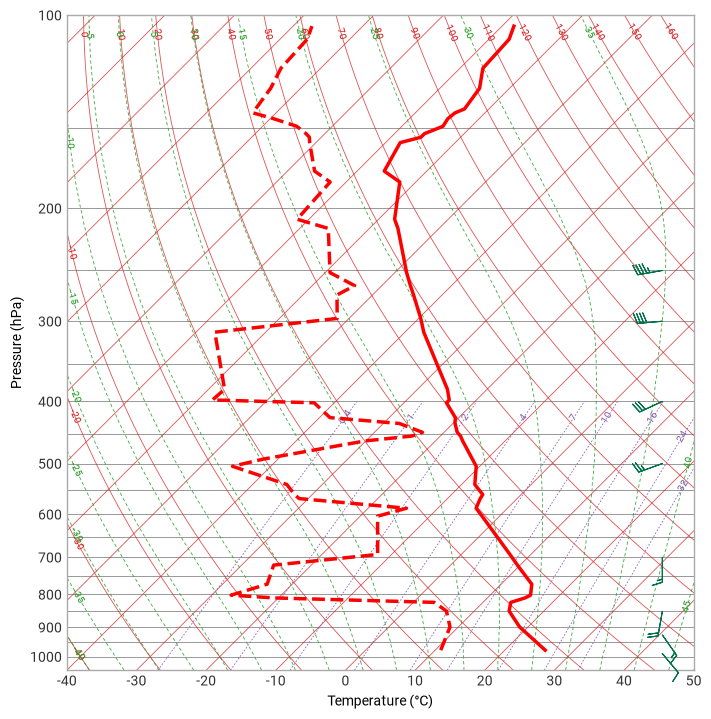

In [7]:
skewt = ekp.SkewT()

skewt.temperature(temperature, p=pressure, color="red", linewidth=2.5)
skewt.dewpoint(dewpoint, p=pressure, color="red", linestyle="--", linewidth=2.5)
skewt.wind(u, v, p=wind_pressure, color="#00734d", position=0.95)

skewt.show()

### What's next?

The next notebook covers [skew-T and emagram diagrams](thermodynamic-skewt-emagram.ipynb),
which share the interface of the tephigram. The thermodynamic diagrams in
the gallery show more: profiles from BUFR soundings, ensemble spread with side
panels, and parcel paths with CAPE and CIN.